# [Taygeta - 19 Tauri](../../../Costellazioni/Taurus/Taygeta.html) del [21/02/2026](../Index.html)

In [1]:
import math
import sys
sys.path.append('../../../src')
import spectrum as spec
import pandas as pd

## Camera Settings

- Gain=100
- Exposure=40.000s
- Brightness=5
- Temperature=-10
- StartCapture=2026-02-21T18:44:01.8657015Z
- EndCapture=2026-02-21T19:25:05.2409728Z




































## Raw Spectrum

Spettro ottenuto come media di 60 immagini. Applicati bias, dark e flat. Elaborazione con ISIS

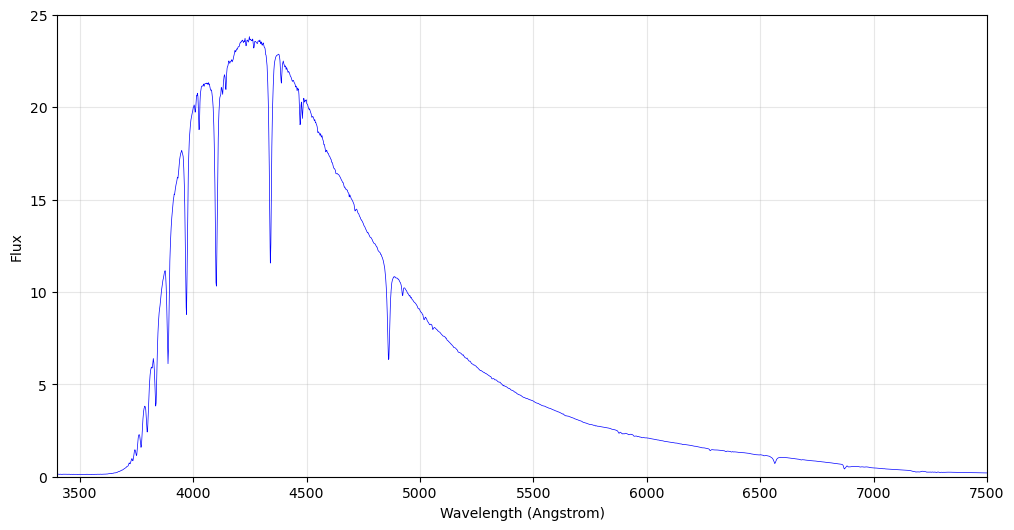

In [2]:
raw_wavelength, raw_flux = spec.load("_taygeta_20260221_781.fit")
raw_flux = spec.cleanup_flux(raw_flux)
spec.simple_plot(raw_wavelength, raw_flux, wl_range = (3400, 7500), flux_range=(0.0,25.0))

## Rectified Spectrum

In [3]:
wavelength, flux = spec.load("_taygeta_20260221_781-rect.fit")
flux = spec.cleanup_flux(flux)
print(f"SNR Reale stimato: {spec.calc_snr(wavelength, flux, 5670, 5820):.1f}")

SNR Reale stimato: 729.3


In [4]:
spectral_lines_summary = pd.read_csv('Taygeta spec - Summary.csv', usecols=[0, 1, 2], names=["name","class","wavelength"])
spectral_lines_all = pd.read_csv('Taygeta spec - 2026-02-21.csv', usecols=[0, 1, 2], names=["name","class","wavelength"], skiprows=1)

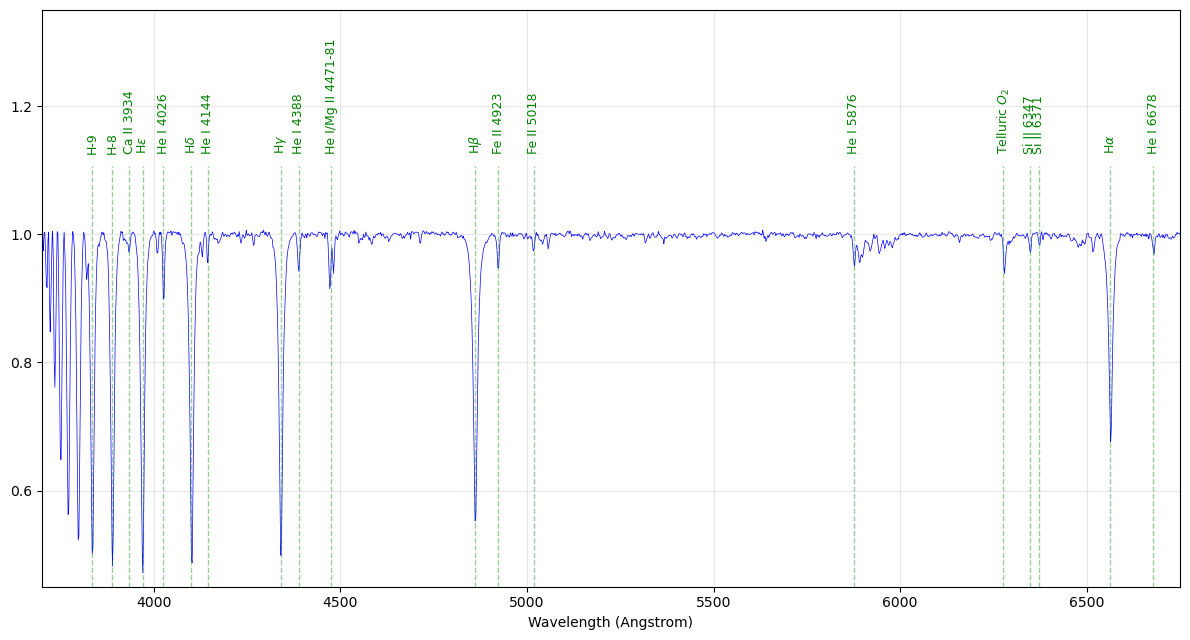

In [5]:
spec.plot_with_lines(wavelength, flux, spectral_lines_summary, (3700,6750), (0.45,1.35))

### Zoom  370 - 400 nm

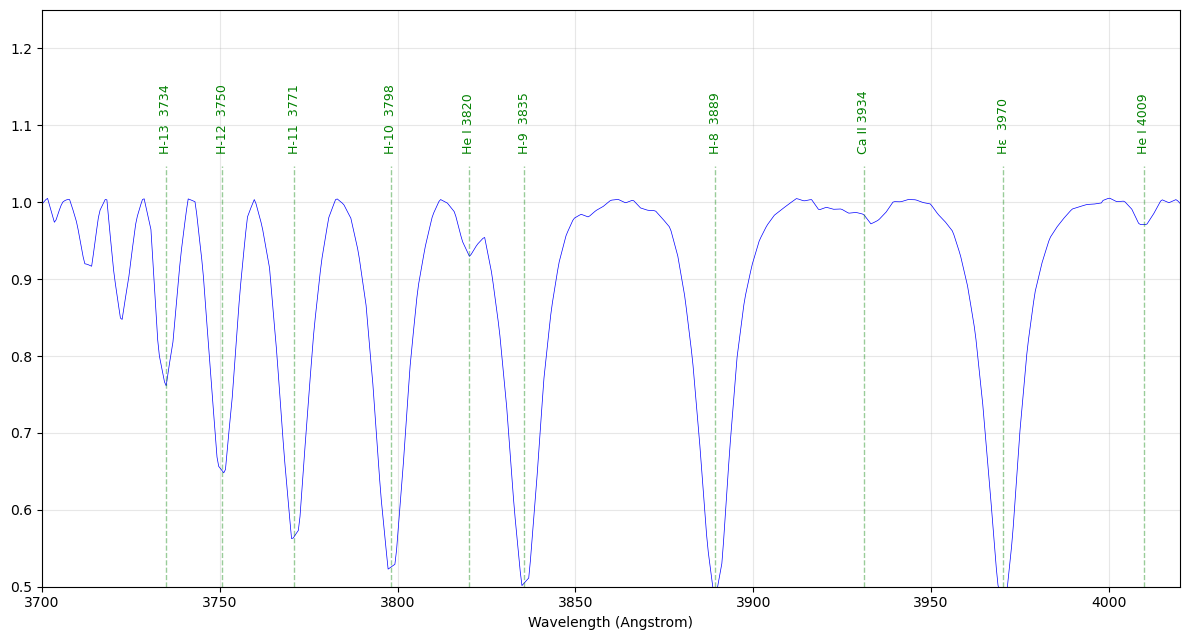

In [6]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (3700,4020), (0.50,1.25))

### Zoom  400 - 430 nm

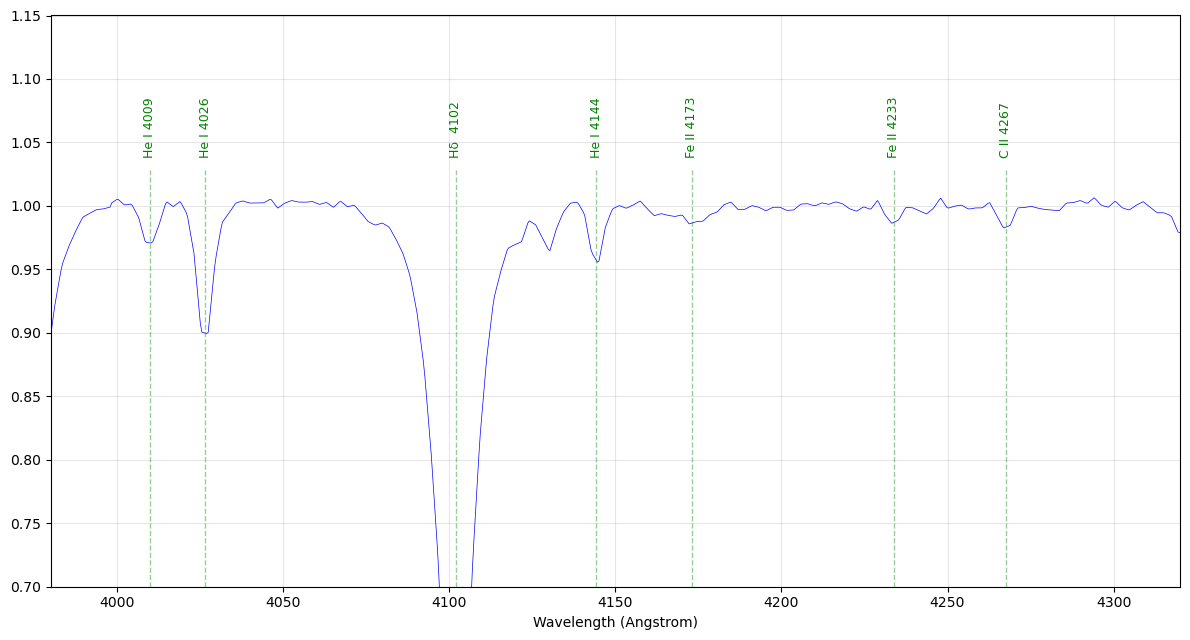

In [7]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (3980,4320), (0.70,1.15))

### Zoom 430 - 460 nm

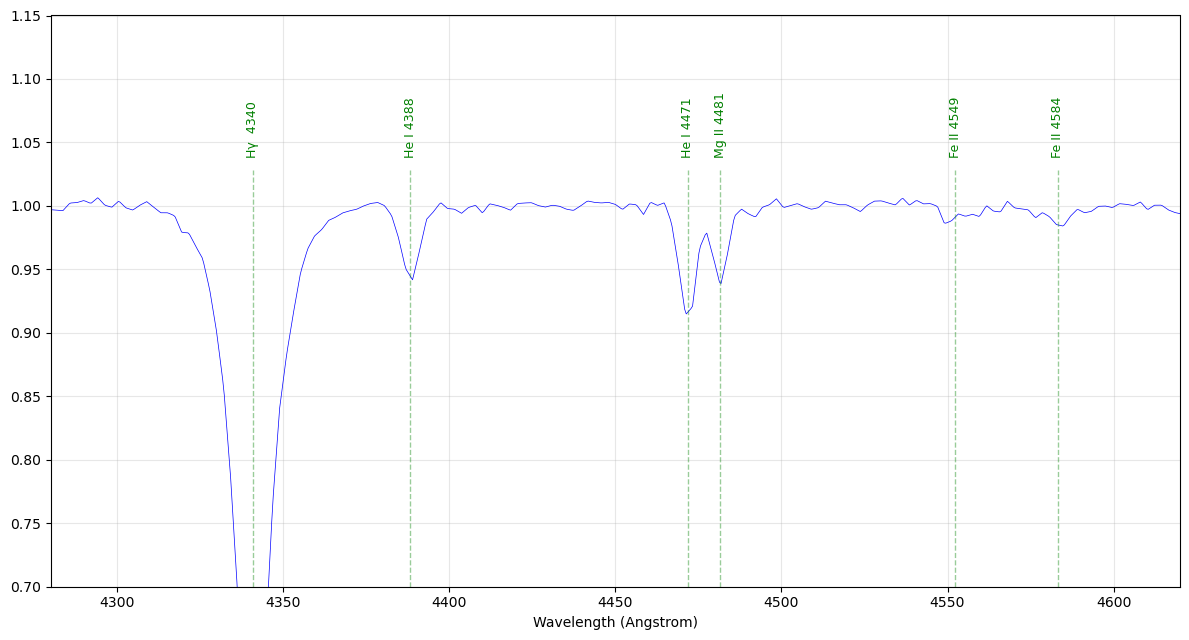

In [8]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4280,4620), (0.70,1.15))

### Zoom  460 - 490 nm

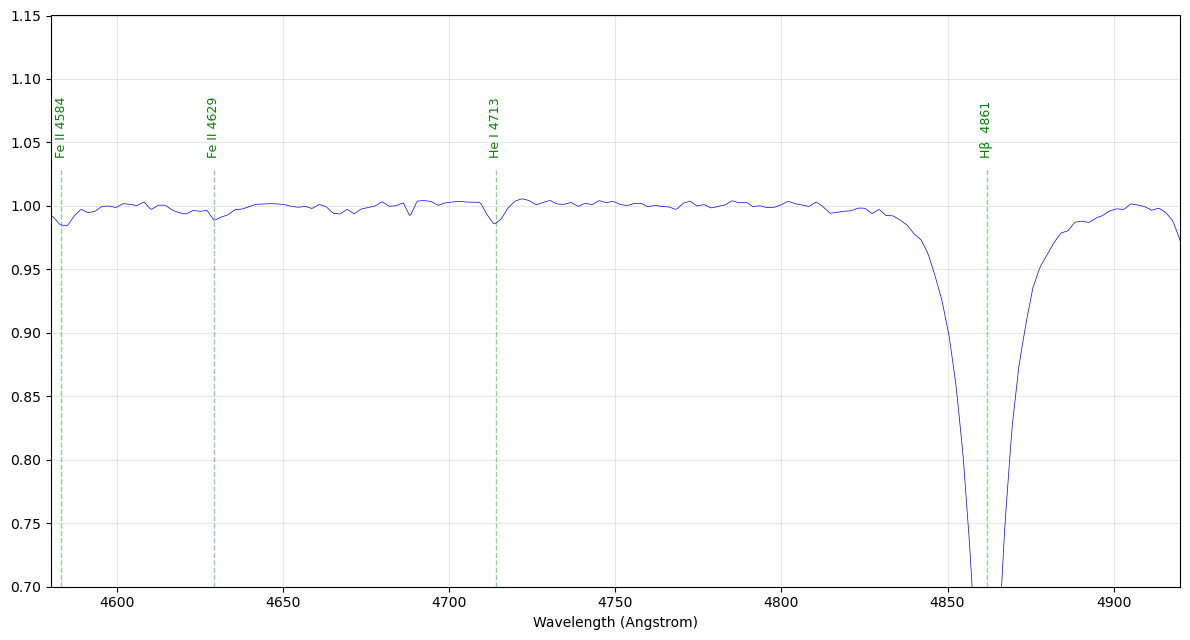

In [9]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4580,4920), (0.70,1.15))

### Zoom  490 - 540 nm

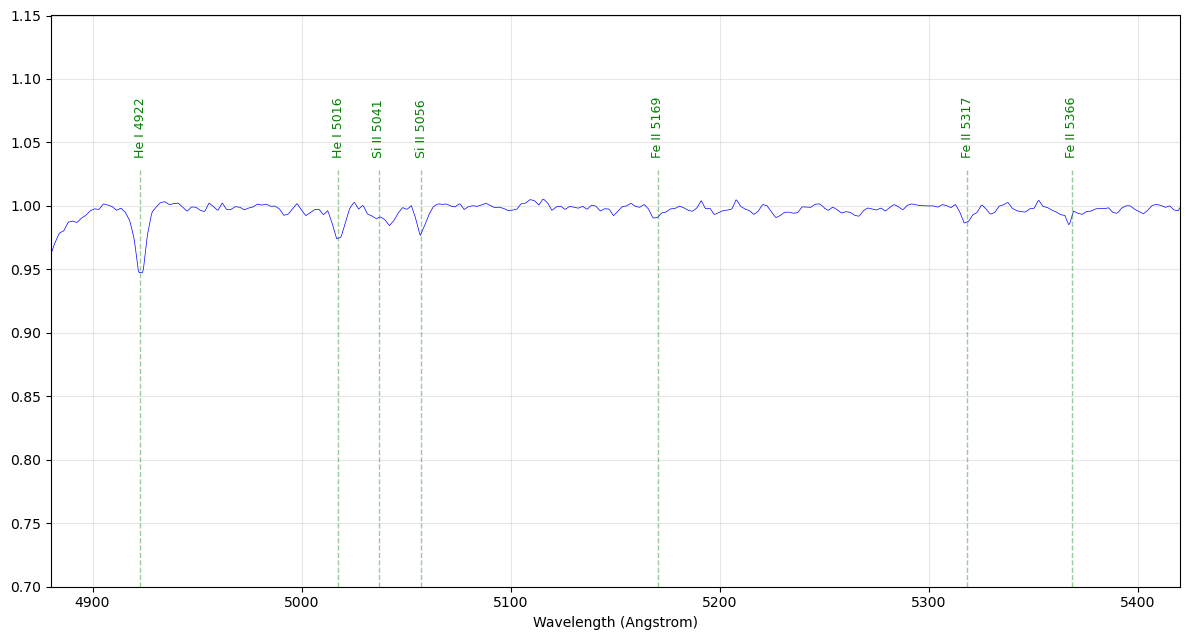

In [10]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4880,5420), (0.70,1.15))

### Zoom  540 - 600 nm

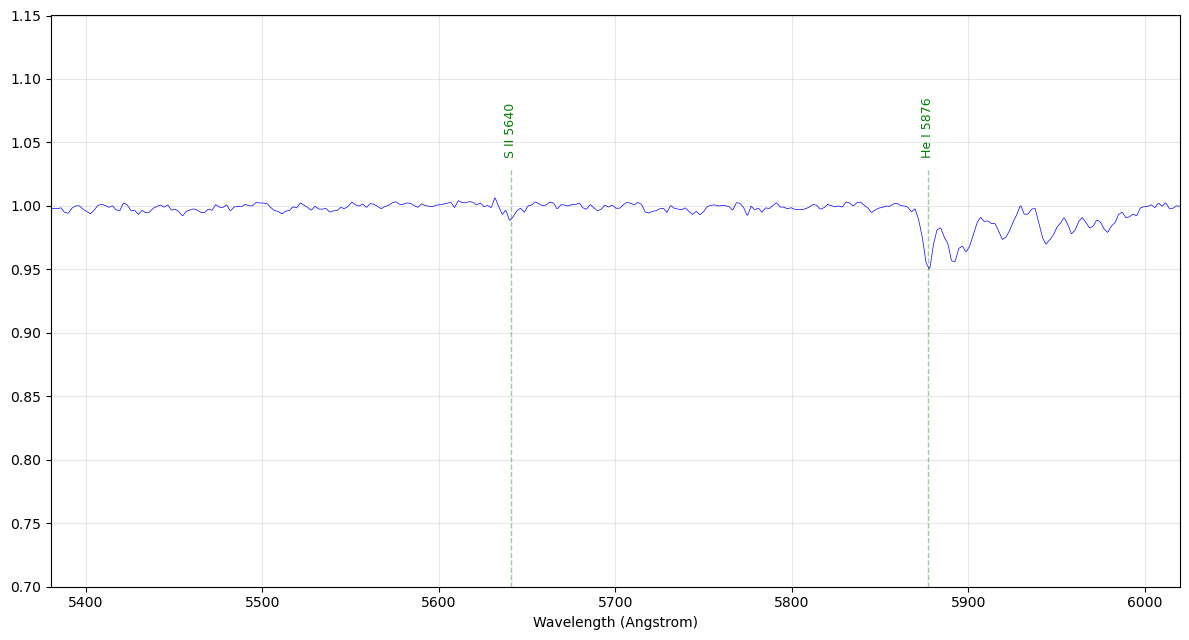

In [11]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (5380,6020), (0.70,1.15))

### Zoom  600 - 680 nm

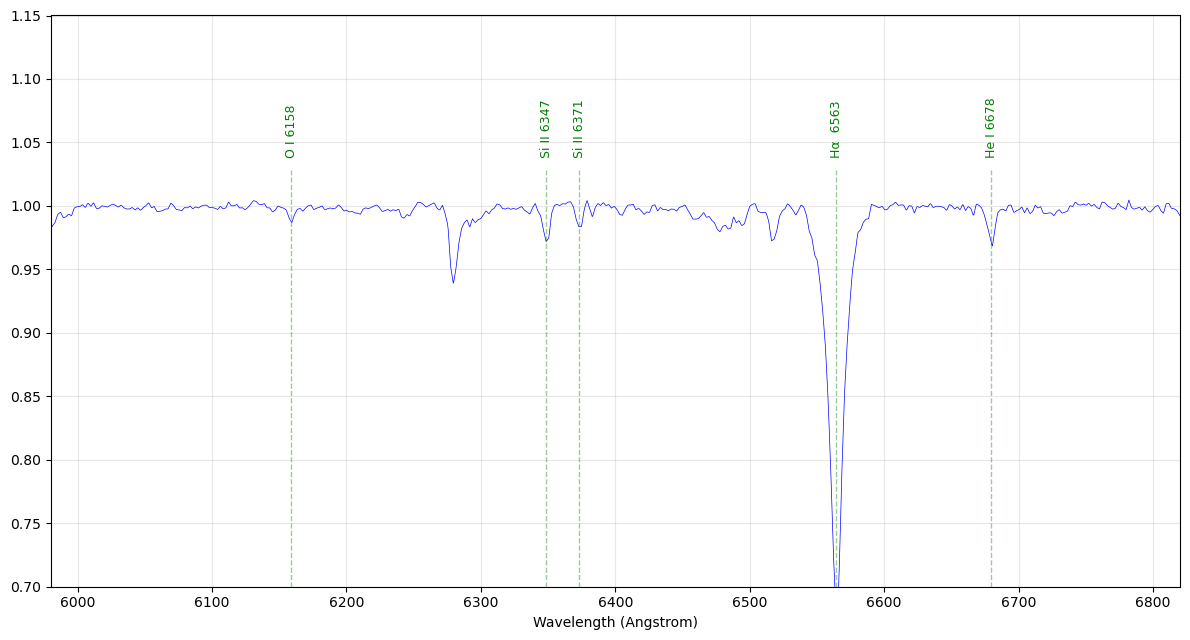

In [12]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (5980,6820), (0.70,1.15))

## Line Measures

In [13]:
final_results = pd.read_csv("line_measured_taygeta_20260221.csv")

In [14]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [15]:
final_results = final_results[final_results["line_name"].apply(lambda s: not s.lower().startswith("unknown"))]

# Relative errors (%)
for col in ["wavelength", "ew", "fwhm", "intensity"]:
    final_results["rel_err_" + col] = 100 * final_results["delta_" + col] / final_results[col].abs()

# Approximate values and errors consistently 
for col in ["wavelength", "ew", "fwhm", "intensity"]:
    rounded = [round_measurement(v, e) for v, e in zip(final_results[col], final_results["delta_" + col])]
    final_results[col] = [r[0] for r in rounded]
    final_results["delta_" + col] = [r[1] for r in rounded]
    # relative error in %, 2 significant figures
    final_results["rel_err_" + col] = final_results["rel_err_" + col].apply(
        lambda x: float(f"{x:.2g}"))

final_results = final_results[["line_name",
    "wavelength", "delta_wavelength", "rel_err_wavelength",
    "ew", "delta_ew", "rel_err_ew",
    "fwhm", "delta_fwhm", "rel_err_fwhm",
    "intensity", "delta_intensity", "rel_err_intensity"]]

# Readable column names
final_results = final_results.rename(columns={
    "line_name": "Line",
    "wavelength": "Wavelength (Å)",
    "delta_wavelength": "Wavelength error (Å)",
    "rel_err_wavelength": "Wavelength rel. error (%)",
    "ew": "EW (Å)",
    "delta_ew": "EW error (Å)",
    "rel_err_ew": "EW rel. error (%)",
    "fwhm": "FWHM (Å)",
    "delta_fwhm": "FWHM error (Å)",
    "rel_err_fwhm": "FWHM rel. error (%)",
    "intensity": "Intensity",
    "delta_intensity": "Intensity error",
    "rel_err_intensity": "Intensity rel. error (%)",
})


In [16]:
# ---------- Formatting helpers ----------
def decimals_from_error(err):
    """Decimals to show, following the round_measurement rule:
    2 significant figures if the error starts with 1 or 2, otherwise 1."""
    exponent = math.floor(math.log10(err))
    first_digit = int(err / 10 ** exponent)
    sig_figs = 2 if first_digit in (1, 2) else 1
    return max(sig_figs - exponent - 1, 0)

def fmt_rel(x):
    """Relative error in %, 2 significant figures, never in scientific notation."""
    if x == 0:
        return "0"
    exp = math.floor(math.log10(abs(x)))
    r = round(x, 1 - exp)                       # round to 2 significant figures
    exp = math.floor(math.log10(abs(r)))        # rounding can raise the exponent (99.6 -> 100)
    return f"{r:.{max(1 - exp, 0)}f}"

# ---------- Find the columns of each group ----------
prefixes = ["Wavelength", "EW", "FWHM", "Intensity"]

def find_cols(prefix):
    cols = [c for c in final_results.columns if c.startswith(prefix)]
    rel = [c for c in cols if "rel" in c.lower()]
    err = [c for c in cols if "error" in c.lower() and c not in rel]
    val = [c for c in cols if c not in rel and c not in err]
    assert len(val) == len(err) == len(rel) == 1, \
        f"Unexpected columns for {prefix}: {cols}"
    return val[0], err[0], rel[0]

# ---------- Build a display copy (strings); final_results stays untouched ----------
display_df = final_results.copy()

for prefix in prefixes:
    val_col, err_col, rel_col = find_cols(prefix)
    decs = final_results[err_col].apply(decimals_from_error)
    display_df[val_col] = [f"{v:.{d}f}" for v, d in zip(final_results[val_col], decs)]
    display_df[err_col] = [f"{e:.{d}f}" for e, d in zip(final_results[err_col], decs)]
    display_df[rel_col] = final_results[rel_col].apply(fmt_rel)

# ---------- Colour the 4 groups of columns + row hover ----------
colors = {
    "Wavelength": "#dbeafe",   # light blue
    "EW":         "#dcfce7",   # light green
    "FWHM":       "#fef9c3",   # light yellow
    "Intensity":  "#fce7f3",   # light pink
}

table_styles = [
    {"selector": "th", "props": [("text-align", "center")]},
    # Row hover: darken every cell a bit, so each group keeps its own colour
    {"selector": "tr:hover td", "props": [("filter", "brightness(0.9)")]},
    # Uncoloured cells (Line column and index) get a light grey overlay instead
    {"selector": "tr:hover td.col0", "props": [("background-color", "rgba(128,128,128,0.15)")]},
    {"selector": "tr:hover th", "props": [("background-color", "rgba(128,128,128,0.15)")]},
]

# One CSS rule per column, using the column's position
for prefix, color in colors.items():
    for c in display_df.columns:
        if c.startswith(prefix):
            i = display_df.columns.get_loc(c)
            table_styles.append({
                "selector": f"td.col{i}",
                "props": [("background-color", color),
                          ("color", "black"),
                          ("text-align", "right")],
            })

styler = display_df.style.set_table_styles(table_styles)

styler

,Line,Wavelength (Å),Wavelength error (Å),Wavelength rel. error (%),EW (Å),EW error (Å),EW rel. error (%),FWHM (Å),FWHM error (Å),FWHM rel. error (%),Intensity,Intensity error,Intensity rel. error (%)
0,He I 6678,6679.68,0.18,0.0027,0.201,0.026,13,6.9,0.8,11,-0.0276,0.0025,9.0
1,H alfa,6564.31,0.03,0.00052,7.01,0.26,3.7,13.4,0.4,2.7,-0.3337,0.0024,0.71
2,Si II 6371,6373.27,0.19,0.0030,0.106,0.014,13,5.7,0.6,11,-0.0176,0.0028,16
3,Si II 6347,6348.80,0.14,0.0022,0.161,0.013,8.2,5.7,0.4,6.6,-0.0265,0.0020,7.7
4,He I 4922,4922.91,0.03,0.00064,0.358,0.011,3.1,6.36,0.15,2.4,-0.0528,0.0007,1.2
5,H beta,4861.800,0.012,0.00024,7.93,0.18,2.2,12.757,0.021,0.17,-0.4386,0.0025,0.57
6,Mg II 4481,4481.487,0.021,0.00046,0.314,0.010,3.2,5.26,0.09,1.6,-0.0562,0.0010,1.8
7,He I 4471,4471.818,0.020,0.00046,0.570,0.020,3.4,6.27,0.14,2.2,-0.0853,0.0011,1.3
8,He I 4388,4388.379,0.029,0.00066,0.280,0.029,10,5.40,0.30,5.9,-0.0487,0.0022,4.4
9,H gamma,4340.806,0.012,0.00029,7.96,0.27,3.3,12.108,0.020,0.16,-0.485,0.004,0.82


[Click here for details](line_measures.html)